<a href="https://colab.research.google.com/github/mstanmay/-Customer-Churn-Prediction-using-Feature-Engineering/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!git clone https://github.com/mstanmay/-Customer-Churn-Prediction-using-Feature-Engineering.git

Cloning into '-Customer-Churn-Prediction-using-Feature-Engineering'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), done.


In [6]:
%cd Customer-Churn-prediction-using-Feature-Engineering

[Errno 2] No such file or directory: 'Customer-Churn-prediction-using-Feature-Engineering'
/content


In [7]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2

from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

Load Dataset


In [11]:
import os
import zipfile
import pandas as pd


os.chdir("/content")

# Extract the zip file
with zipfile.ZipFile("Telco_customer_churn.xlsx.zip", "r") as zip_ref:
    zip_ref.extractall(".")

# Load the extracted Excel file (using pandas read_excel)
df = pd.read_excel("Telco_customer_churn.xlsx")

print(df.head())
print(df.shape)
print(df.info())

   CustomerID  Count        Country       State         City  Zip Code  \
0  3668-QPYBK      1  United States  California  Los Angeles     90003   
1  9237-HQITU      1  United States  California  Los Angeles     90005   
2  9305-CDSKC      1  United States  California  Los Angeles     90006   
3  7892-POOKP      1  United States  California  Los Angeles     90010   
4  0280-XJGEX      1  United States  California  Los Angeles     90015   

                 Lat Long   Latitude   Longitude  Gender  ...        Contract  \
0  33.964131, -118.272783  33.964131 -118.272783    Male  ...  Month-to-month   
1   34.059281, -118.30742  34.059281 -118.307420  Female  ...  Month-to-month   
2  34.048013, -118.293953  34.048013 -118.293953  Female  ...  Month-to-month   
3  34.062125, -118.315709  34.062125 -118.315709  Female  ...  Month-to-month   
4  34.039224, -118.266293  34.039224 -118.266293    Male  ...  Month-to-month   

  Paperless Billing             Payment Method  Monthly Charges Tota

Data Cleaning


In [28]:
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)

# Drop only rows where critical features like 'Total Charges' are null.
# Do not drop rows globally, otherwise we lose all non-churned customers (whose 'Churn Reason' is NaN)!
df = df.dropna(subset=["Total Charges"])

In [14]:
print(df.isnull().sum())

CustomerID           0
Count                0
Country              0
State                0
City                 0
Zip Code             0
Lat Long             0
Latitude             0
Longitude            0
Gender               0
Senior Citizen       0
Partner              0
Dependents           0
Tenure Months        0
Phone Service        0
Multiple Lines       0
Internet Service     0
Online Security      0
Online Backup        0
Device Protection    0
Tech Support         0
Streaming TV         0
Streaming Movies     0
Contract             0
Paperless Billing    0
Payment Method       0
Monthly Charges      0
Total Charges        0
Churn Label          0
Churn Value          0
Churn Score          0
CLTV                 0
Churn Reason         0
dtype: int64


Remove Unnecessary Features

In [36]:
df = df.drop("CustomerID", axis=1, errors="ignore")

In [34]:
df["Churn"] = df["Churn Label"].map({
    "Yes": 1,
    "No": 0
})

In [33]:
# Defining X as the dataset features (excluding the target variable 'Churn' if needed)
X = df.drop(columns=['Churn', 'Churn Label', 'Churn Value', 'Churn Reason'], errors='ignore')

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
Index(['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months',
       'Monthly Charges', 'Total Charges', 'Churn Score', 'CLTV'],
      dtype='object')

Categorical features:
Index(['Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Phone Service', 'Multiple Lines',
       'Internet Service', 'Online Security', 'Online Backup',
       'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies',
       'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='object')


Encode Categorical Features

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

Train-Test Split

In [24]:
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Logistic Regression

In [40]:
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)
y_pred = logistic_model.predict(X_test)

print("Model training completed successfully!")
print(f"Training set shape: {X_train.shape}")
print(f"Target class distribution in y_train:\n{y_train.value_counts()}")

Model training completed successfully!
Training set shape: (5625, 29)
Target class distribution in y_train:
Churn
0    4130
1    1495
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [41]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.9168443496801706
Precision: 0.8445040214477212
Recall   : 0.8422459893048129
F1 Score : 0.8433734939759037


In [42]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.94      0.94      1033
           1       0.84      0.84      0.84       374

    accuracy                           0.92      1407
   macro avg       0.89      0.89      0.89      1407
weighted avg       0.92      0.92      0.92      1407



Feature Selection

In [43]:
X_encoded = pd.get_dummies(
    X,
    drop_first=True
)

X_encoded = X_encoded.astype(int)

In [45]:
from sklearn.preprocessing import MinMaxScaler

# Scale the features to [0, 1] to make all values non-negative for the chi2 test
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_encoded)

selector = SelectKBest(
    score_func=chi2,
    k=10
)

X_selected = selector.fit_transform(
    X_scaled,
    y
)

# Print the selected features
selected_features = X_encoded.columns[selector.get_support()]
print("Top 10 Selected Features:")
print(selected_features.tolist())

Top 10 Selected Features:
['Dependents_Yes', 'Internet Service_Fiber optic', 'Online Security_No internet service', 'Online Backup_No internet service', 'Device Protection_No internet service', 'Tech Support_No internet service', 'Streaming TV_No internet service', 'Streaming Movies_No internet service', 'Contract_Two year', 'Payment Method_Electronic check']


In [46]:
selected_features = X_encoded.columns[
    selector.get_support()
]

print("Selected Features:")
print(selected_features)

Selected Features:
Index(['Dependents_Yes', 'Internet Service_Fiber optic',
       'Online Security_No internet service',
       'Online Backup_No internet service',
       'Device Protection_No internet service',
       'Tech Support_No internet service', 'Streaming TV_No internet service',
       'Streaming Movies_No internet service', 'Contract_Two year',
       'Payment Method_Electronic check'],
      dtype='object')


Standardization Before PCA

In [47]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_encoded
)

PCA-

In [48]:
pca = PCA(n_components=10)

X_pca = pca.fit_transform(
    X_scaled
)

print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

Original shape: (7032, 2815)
PCA shape: (7032, 10)


In [49]:
print(
    pca.explained_variance_ratio_
)

[0.0037142  0.00166294 0.00157251 0.00119791 0.00076512 0.0007322
 0.00072793 0.00072319 0.00071957 0.00071721]


In [50]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

print(cumulative_variance)

[0.0037142  0.00537713 0.00694964 0.00814755 0.00891268 0.00964488
 0.01037281 0.011096   0.01181557 0.01253278]


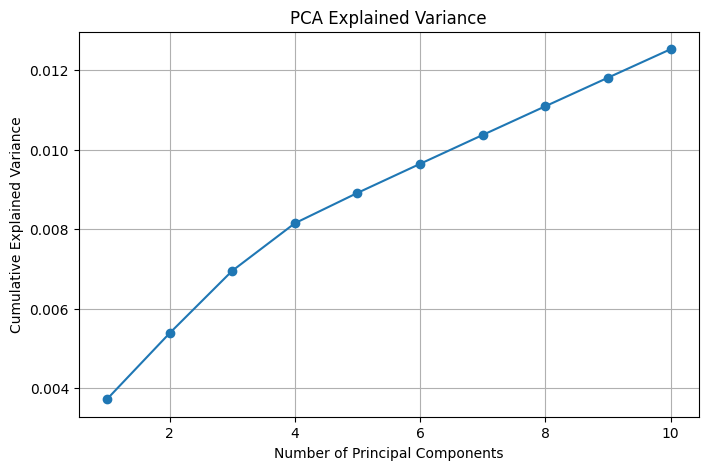

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")

plt.grid()
plt.show()

PCA + Logistic Regression

In [53]:
from sklearn.model_selection import train_test_split

# Split the PCA-reduced features into train and test sets
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

pca_model = LogisticRegression(
    max_iter=1000
)

pca_model.fit(
    X_train_pca,
    y_train_pca
)

y_pred_pca = pca_model.predict(
    X_test_pca
)

print("PCA Logistic Regression trained successfully!")
print(f"PCA Train set shape: {X_train_pca.shape}")
print(f"PCA Test set shape: {X_test_pca.shape}")

PCA Logistic Regression trained successfully!
PCA Train set shape: (5625, 10)
PCA Test set shape: (1407, 10)


In [54]:
accuracy_pca = accuracy_score(y_test_pca, y_pred_pca)
precision_pca = precision_score(y_test_pca, y_pred_pca)
recall_pca = recall_score(y_test_pca, y_pred_pca)
f1_pca = f1_score(y_test_pca, y_pred_pca)

print("=== PCA Logistic Regression Metrics ===")
print("Accuracy :", accuracy_pca)
print("Precision:", precision_pca)
print("Recall   :", recall_pca)
print("F1 Score :", f1_pca)

print("\n=== Classification Report ===")
print(classification_report(y_test_pca, y_pred_pca))

=== PCA Logistic Regression Metrics ===
Accuracy : 0.8045486851457001
Precision: 0.6523076923076923
Recall   : 0.5668449197860963
F1 Score : 0.6065808297567954

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [55]:
print(
    classification_report(
        y_test_pca,
        y_pred_pca
    )
)

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [56]:
rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [57]:
print("Accuracy:",
      accuracy_score(y_test, rf_pred))

print("Precision:",
      precision_score(y_test, rf_pred))

print("Recall:",
      recall_score(y_test, rf_pred))

print("F1 Score:",
      f1_score(y_test, rf_pred))

Accuracy: 0.9196872778962332
Precision: 0.8966565349544073
Recall: 0.7887700534759359
F1 Score: 0.8392603129445235


In [58]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[975  58]
 [ 59 315]]


Feature Engineering

In [60]:
df["TenureGroup"] = pd.cut(
    df["Tenure Months"],
    bins=[0, 12, 24, 48, 72],
    labels=[
        "0-1 Year",
        "1-2 Years",
        "2-4 Years",
        "4+ Years"
    ]
)

In [64]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

print("Visualization module loaded successfully!")

Visualization module loaded successfully!


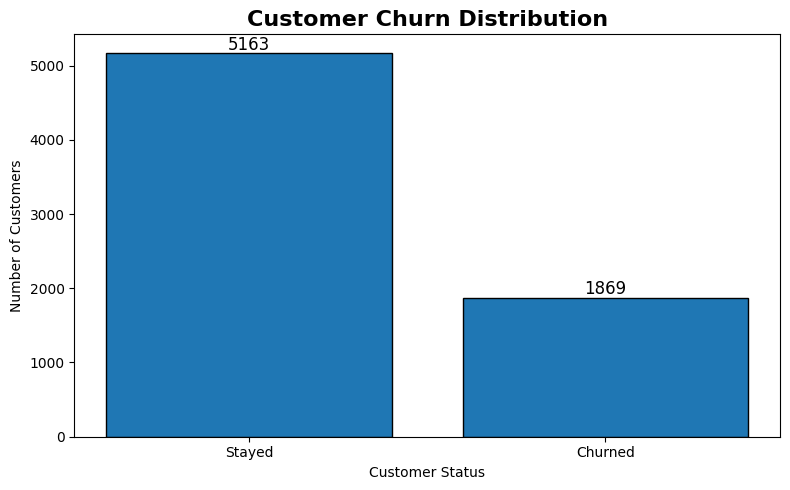

In [65]:
# ============================================================
# VISUALIZATION 1 – CHURN DISTRIBUTION
# ============================================================

churn_counts = df["Churn"].value_counts().sort_index()

labels = ["Stayed", "Churned"]
values = [
    churn_counts.get(0, 0),
    churn_counts.get(1, 0)
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    values,
    edgecolor="black"
)

plt.title(
    "Customer Churn Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

for bar, value in zip(bars, values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        str(value),
        ha="center",
        fontsize=12
    )

plt.tight_layout()
plt.show()

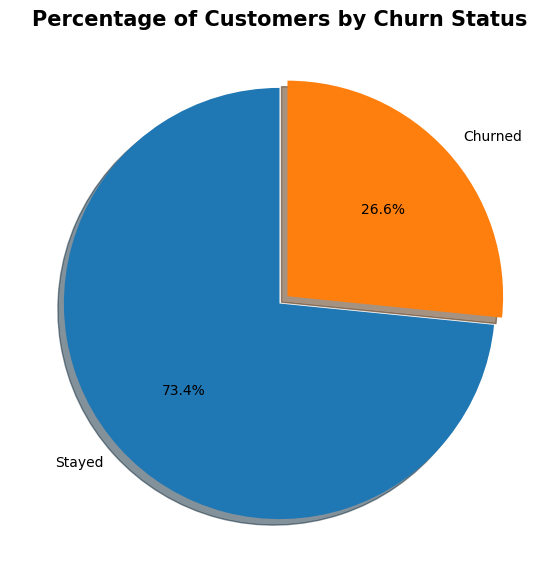

In [66]:
# ============================================================
# VISUALIZATION 2 – CHURN PERCENTAGE
# ============================================================

churn_percent = df["Churn"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    churn_percent,
    labels=["Stayed", "Churned"],
    autopct="%1.1f%%",
    startangle=90,
    explode=[0, 0.05],
    shadow=True
)

plt.title(
    "Percentage of Customers by Churn Status",
    fontsize=15,
    fontweight="bold"
)

plt.show()

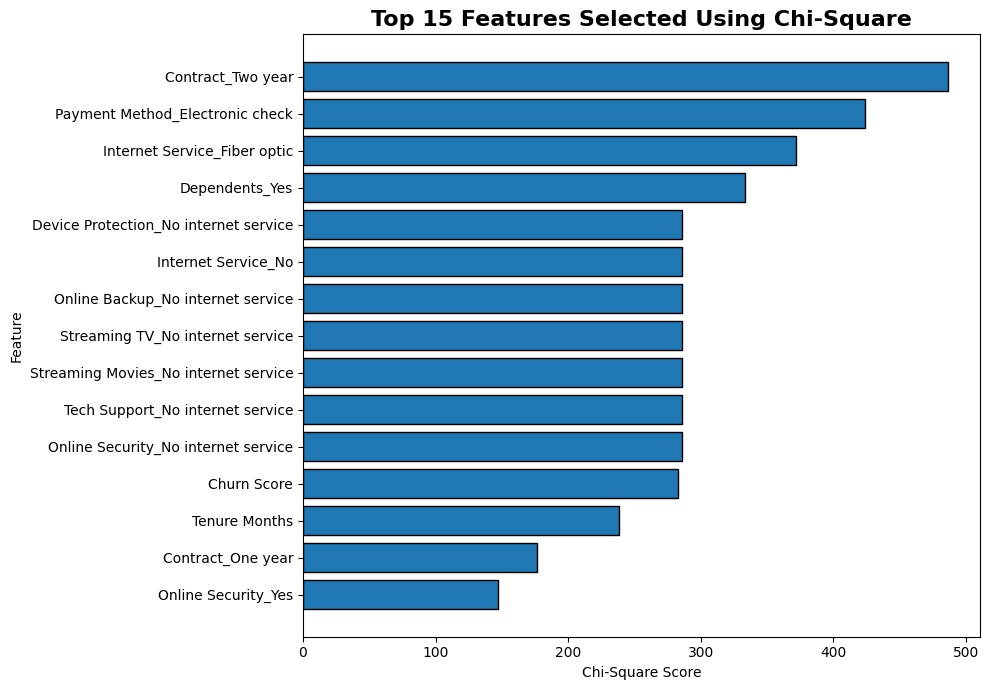

In [68]:
# ============================================================
# VISUALIZATION 9 – FEATURE SELECTION
# ============================================================

# Recreate the feature_scores DataFrame using the selector scores
feature_scores = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Chi2_Score": selector.scores_
})

top_features = (
    feature_scores
    .sort_values(
        "Chi2_Score",
        ascending=False
    )
    .head(15)
    .sort_values(
        "Chi2_Score"
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Chi2_Score"],
    edgecolor="black"
)

plt.title(
    "Top 15 Features Selected Using Chi-Square",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Chi-Square Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [69]:
!git add .

fatal: not a git repository (or any of the parent directories): .git


In [70]:
!git commit -m "Updated churn prediction project"

fatal: not a git repository (or any of the parent directories): .git


In [71]:
!git push origin main

fatal: not a git repository (or any of the parent directories): .git


In [72]:
!git clone https://github.com/mstanmay/-Customer-Churn-Prediction-using-Feature-Engineering.git

fatal: destination path '-Customer-Churn-Prediction-using-Feature-Engineering' already exists and is not an empty directory.


In [73]:
!git push origin main

fatal: not a git repository (or any of the parent directories): .git


In [74]:
!git clone https://github.com/mstanmay/-Customer-Churn-Prediction-using-Feature-Engineering.git

fatal: destination path '-Customer-Churn-Prediction-using-Feature-Engineering' already exists and is not an empty directory.


In [75]:
!git commit -m "Updated churn prediction project"

fatal: not a git repository (or any of the parent directories): .git


In [76]:
!git status

fatal: not a git repository (or any of the parent directories): .git


In [77]:
!pwd

/content


In [78]:
!ls

-Customer-Churn-Prediction-using-Feature-Engineering
sample_data
Telco_customer_churn.xlsx
Telco_customer_churn.xlsx.zip


In [79]:
!git clone https://github.com/mstanmay/-Customer-Churn-Prediction-using-Feature-Engineering.git

fatal: destination path '-Customer-Churn-Prediction-using-Feature-Engineering' already exists and is not an empty directory.


In [80]:
!ls -la /content

total 2644
drwxr-xr-x 1 root root    4096 Oct  6 13:38 .
drwxr-xr-x 1 root root    4096 Oct  6 13:17 ..
drwxr-xr-x 4 root root    4096 Oct  2 13:50 .config
drwxr-xr-x 3 root root    4096 Oct  6 13:31 -Customer-Churn-Prediction-using-Feature-Engineering
drwxr-xr-x 1 root root    4096 Oct  2 13:50 sample_data
-rw-r--r-- 1 root root 1368250 Oct  6 13:38 Telco_customer_churn.xlsx
-rw-r--r-- 1 root root 1314646 Oct  6 13:30 Telco_customer_churn.xlsx.zip


In [81]:
!git -C "/content/-Customer-Churn-Prediction-using-Feature-Engineering" status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [82]:
%cd "/content/-Customer-Churn-Prediction-using-Feature-Engineering"

/content/-Customer-Churn-Prediction-using-Feature-Engineering


In [83]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [84]:
%cd /content/customer-churn-prediction

[Errno 2] No such file or directory: '/content/customer-churn-prediction'
/content/-Customer-Churn-Prediction-using-Feature-Engineering


In [85]:
!git remote -v

origin	https://github.com/mstanmay/-Customer-Churn-Prediction-using-Feature-Engineering.git (fetch)
origin	https://github.com/mstanmay/-Customer-Churn-Prediction-using-Feature-Engineering.git (push)


In [86]:
!mkdir -p notebooks data src outputs